# Chapter 17 · Arbitrage-free option surfaces: interactive demos

Companion to Chapter 17 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf),
which presents SANOS (Buehler, Horvath, Kratsios, Limmer and Saqur, arXiv:2601.11209) and DYSANOS (Buehler, Horvath,
Kratsios and Wiese, arXiv:2608.12587). Each section draws a figure with default settings, then an **Explore** cell lets you
move the parameters. The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/17-arbitrage-free-surfaces.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

**Data.** Sections 1–6 use the synthetic market of the notes: the Heston model of Chapter 15 quoted at six expiries with
bid–ask spreads, so the notebook runs offline. Section 7 downloads, at run time, a real implied-volatility surface: the DAX
surface (13 strikes, 8 maturities) that A. Sepp used in *Pricing European-style options under jump diffusion processes with
stochastic volatility*, as distributed in the test suite of [QuantLib](https://github.com/lballabio/QuantLib)
(`test-suite/hestonmodel.cpp`, QuantLib's BSD-style licence). It has mid volatilities only, so the spreads are assumed.
Without network access, or with the environment variable `IEOR222_OFFLINE` set (as when this notebook was saved), Section 7
falls back to the synthetic market. To use your own quotes, build for each expiry a dict
with the normalized strikes `x = K / F_T` and the normalized prices `bid`, `ask`, `mid` (call price times $e^{rT}/F_T$),
as `load_quotes` does in Section 7, and pass the list to `sanos_calibrate`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

import os, re, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from ieor222 import surfaces as S
from ieor222.volatility import black_normalized, heston_call, heston_surface
from ieor222.style import COBALT, GOLD, GREY, INK, PALETTE, use_style

GREEN = PALETTE[2]
use_style()
plt.rcParams["figure.dpi"] = 80   # keeps the notebook small

def iv(c, x, T):
    """Implied volatility (%) of normalized call prices."""
    return 100 * np.sqrt(S.implied_total_variance(c, x) / T)

## 1. Naive interpolation creates arbitrage

The quotes: the Heston market of Chapter 15 ($v_0=\theta=0.04$, $\kappa=2$, $\xi=0.5$, $\rho=-0.7$) at 1, 2, 3, 6, 9 and 12
months, 21 strikes per expiry, half-spreads of `spread` volatility points times the vega (at least $10^{-4}$), and mids off
the Heston price by up to `noise` half-spreads. Interpolating the mid total variance linearly in log-moneyness gives a kink
at every quote; at a concave kink the implied law has a negative atom (Proposition 17.1). A cubic spline has no kinks but
oscillates. The right panel shows the implied densities of $\log Z_T$ and marks the concave kinks; the printout counts the
butterflies of adjacent *mid* quotes that are already negative (the conditions of Theorem 17.6).

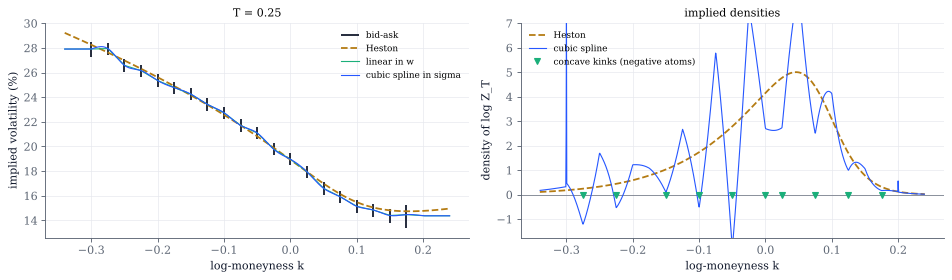

concave kinks at this expiry: 10 of 19 inner quotes; negative butterflies of adjacent mids, by expiry: [0, 0, 1, 1, 2, 2]


In [2]:
def naive(expiry=2, spread=0.5, noise=0.8, seed=17):
    quotes = S.heston_quotes(S.T_MODEL, S.HESTON, seed=seed, half_spread_vol=spread / 100, noise=noise)
    qt, T = quotes[expiry], S.T_MODEL[expiry]
    k = np.linspace(np.log(qt["x"][0]) - 0.04, np.log(qt["x"][-1]) + 0.04, 1201); x = np.exp(k)
    lin = S.naive_vol(quotes, S.T_MODEL, "linear")(T, x)
    spl = S.naive_vol(quotes, S.T_MODEL, "spline")(T, x)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
    ax.vlines(np.log(qt["x"]), iv(qt["bid"], qt["x"], T), iv(qt["ask"], qt["x"], T), color=INK, label="bid-ask")
    ax.plot(k, iv(heston_call(1.0, x, T, 0.0, **S.HESTON), x, T), color=GOLD, ls="--", label="Heston")
    ax.plot(k, iv(lin, x, T), color=GREEN, lw=1, label="linear in w")
    ax.plot(k, iv(spl, x, T), color=COBALT, lw=1, label="cubic spline in sigma")
    ax.set(xlabel="log-moneyness k", ylabel="implied volatility (%)", title=f"T = {T:.3g}"); ax.legend(fontsize=8)
    def dens(c):
        s = np.diff(c) / np.diff(x)
        return x[1:-1] * np.diff(s) / (0.5 * (x[2:] - x[:-2]))
    ax2.axhline(0, color=GREY, lw=0.6)
    ax2.plot(k, heston_surface(k, [T], **S.HESTON)["density"][0], color=GOLD, ls="--", label="Heston")
    ax2.plot(k[1:-1], dens(spl), color=COBALT, lw=1, label="cubic spline")
    kinks = S.concave_kinks(np.log(qt["x"]), S.implied_total_variance(qt["mid"], qt["x"]))
    ax2.plot(np.log(qt["x"][kinks]), np.zeros(kinks.size), "v", color=GREEN, label="concave kinks (negative atoms)")
    top = 1.4 * heston_surface(k, [T], **S.HESTON)["density"][0].max()
    ax2.set(xlabel="log-moneyness k", ylabel="density of log Z_T", ylim=(-0.25 * top, top), title="implied densities")
    ax2.legend(fontsize=8); fig.tight_layout(); plt.show()
    bad = [S.grid_arbitrage(q["x"], q["mid"][None, :])["n_butterfly"] for q in quotes]
    print(f"concave kinks at this expiry: {len(kinks)} of {len(qt['x']) - 2} inner quotes; "
          f"negative butterflies of adjacent mids, by expiry: {bad}")

naive()

In [3]:
# Explore: with noise = 0 the mids are Heston prices; do the kinks disappear? Widen the spreads and watch the wings.
interact(naive,
         expiry=IntSlider(value=2, min=0, max=5, continuous_update=False, description="expiry"),
         spread=FloatSlider(value=0.5, min=0.05, max=2.0, step=0.05, continuous_update=False, description="spread (pts)"),
         noise=FloatSlider(value=0.8, min=0.0, max=0.99, step=0.01, continuous_update=False, description="noise"),
         seed=IntSlider(value=17, min=0, max=50, continuous_update=False, description="seed"));

## 2. SANOS by linear programming

SANOS replaces each atom $K^i$ of a discrete law by a lognormal law of total variance $v(T)$ (Definition 17.7); the
resulting surface is strictly free of static arbitrage whenever the weights $q_j$ form a martingale density and $v$ is
nondecreasing (Theorem 17.8). The weights are fitted by the linear program of Proposition 17.9, solved here by
`scipy.optimize.linprog` (HiGHS), with $\eta=0.25$, the default of SANOS, and the weights $1/(\text{ask}-\text{bid})$. The left
panel shows the fit at three expiries in implied volatility, the right panel the nonzero weights of the program (a vertex
of the feasible polytope) and the smoothed density at the chosen expiry. The printout reports the share of prices inside
their spreads and the static-arbitrage checks of the fitted surface on a fine grid of strikes and maturities.

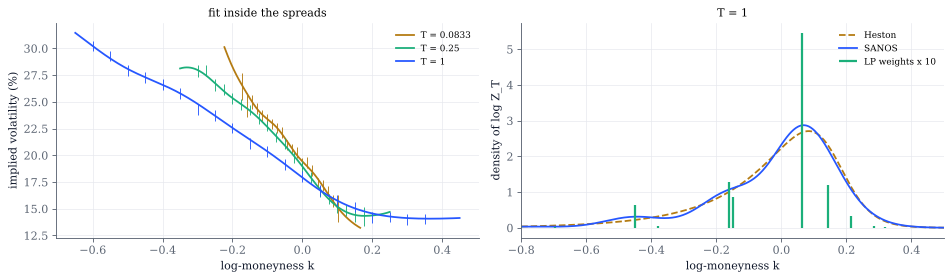

80 model strikes; 100.0% of the 126 prices inside their spreads; nonzero weights per expiry: [9, 8, 11, 10, 11, 13]
checks on a fine grid (>= 0 up to rounding): density -9.6e-10, calendar -1.1e-11; bound violation 1.2e-11


In [4]:
def sanos(spread=0.5, noise=0.8, n_z=41, expiry=5, seed=17):
    quotes = S.heston_quotes(S.T_MODEL, S.HESTON, seed=seed, half_spread_vol=spread / 100, noise=noise)
    K = S.strike_grid(S.T_MODEL, n_z=n_z)
    V = np.maximum.accumulate([S.atm_variance_from_quotes(q) for q in quotes]); v = S.ETA * V
    fit = S.sanos_calibrate(K, quotes, v)
    if fit["status"] != 0:
        print("linear program failed:", fit["message"]); return
    inside, excess = S.within_bid_ask(fit["c"], quotes)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
    for j, c in zip((0, 2, 5), (GOLD, GREEN, COBALT)):
        qt, T = quotes[j], S.T_MODEL[j]
        k = np.linspace(np.log(qt["x"][0]) - 0.05, np.log(qt["x"][-1]) + 0.05, 300); x = np.exp(k)
        ax.vlines(np.log(qt["x"]), iv(qt["bid"], qt["x"], T), iv(qt["ask"], qt["x"], T), color=c, lw=0.8)
        ax.plot(k, iv(S.sanos_surface(fit["q"], K, S.T_MODEL, v, T, x), x, T), color=c, label=f"T = {T:.3g}")
    ax.set(xlabel="log-moneyness k", ylabel="implied volatility (%)", title="fit inside the spreads"); ax.legend(fontsize=8)
    T = S.T_MODEL[expiry]; k = np.linspace(-0.8, 0.5, 600); x = np.exp(k)
    ax2.plot(k, heston_surface(k, [T], **S.HESTON)["density"][0], color=GOLD, ls="--", label="Heston")
    ax2.plot(k, x * S.sanos_density(fit["q"][expiry], K, x, v[expiry]), color=COBALT, label="SANOS")
    nz = fit["q"][expiry] > 1e-10
    ax2.vlines(np.log(K[nz]), 0, 10 * fit["q"][expiry][nz], color=GREEN, lw=2, label="LP weights x 10")
    ax2.set(xlabel="log-moneyness k", ylabel="density of log Z_T", title=f"T = {T:.3g}", xlim=(k[0], k[-1]))
    ax2.legend(fontsize=8); fig.tight_layout(); plt.show()
    xg = np.exp(np.linspace(-1.2, 0.8, 801)); Tg = np.linspace(0.01, 1.2, 60)
    chk = S.surface_checks(lambda t, xx: S.sanos_surface(fit["q"], K, S.T_MODEL, v, t, xx), Tg, xg)
    print(f"{K.size} model strikes; {100 * inside:.1f}% of the {excess.size} prices inside their spreads; "
          f"nonzero weights per expiry: {[int((qj > 1e-10).sum()) for qj in fit['q']]}")
    print(f"checks on a fine grid (>= 0 up to rounding): density {chk['butterfly']:.1e}, calendar {chk['calendar']:.1e}; "
          f"bound violation {chk['bounds']:.1e}")

sanos()

In [5]:
# Explore: narrow the spreads until the fit misses some quotes; coarsen the model grid; change the noise.
interact(sanos,
         spread=FloatSlider(value=0.5, min=0.02, max=2.0, step=0.02, continuous_update=False, description="spread (pts)"),
         noise=FloatSlider(value=0.8, min=0.0, max=0.99, step=0.01, continuous_update=False, description="noise"),
         n_z=IntSlider(value=41, min=11, max=81, step=2, continuous_update=False, description="grid points"),
         expiry=IntSlider(value=5, min=0, max=5, continuous_update=False, description="expiry"),
         seed=IntSlider(value=17, min=0, max=50, continuous_update=False, description="seed"));

## 3. Discrete local volatility and Dupire

For any discrete local volatilities $\Sigma\ge0$, the inverse of the tri-band matrix $\mathbf M$ is a martingale transition
matrix (Proposition 17.10(i)); conversely, a strictly positive martingale density determines its discrete local
volatilities by a finite-difference Dupire formula (Proposition 17.10(ii)). Below, the left panel applies that formula to
Heston prices at maturities $T-\Delta$ and $T$ on a grid uniform in $\log x$ with spacing $h$, and compares with the Dupire
local volatility of Chapter 15. The right panel goes the other way: it propagates the unit mass at the forward with a
constant discrete local volatility and shows the laws $q_j$, whose boundary strikes absorb mass.

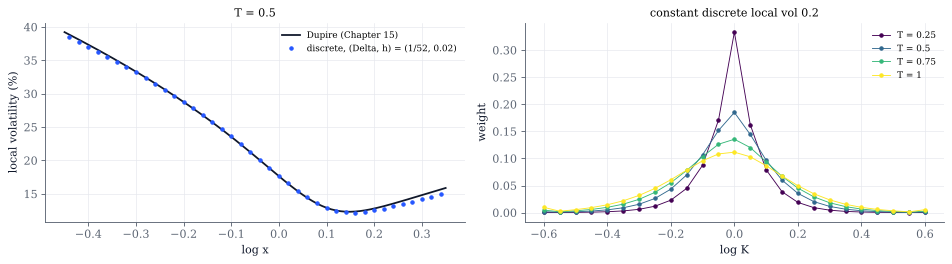

largest gap on log x in [-0.45, 0.35]: 0.73 volatility points; means of the q_j: [1. 1. 1. 1.]


In [6]:
GRIDS = {"(1/12, 0.05)": (1 / 12, 0.05), "(1/52, 0.02)": (1 / 52, 0.02), "(1/252, 0.01)": (1 / 252, 0.01)}

def dlv(grid="(1/52, 0.02)", T=0.5, sigma=0.2, steps=4):
    dT, h = GRIDS[grid]
    ke = np.linspace(-0.45, 0.35, 161)
    lv = S.dupire_reference(T, ke)
    y, sig = S.heston_implied_dlv(T, dT, h)
    keep = (y >= ke[0]) & (y <= ke[-1])
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 3.4))
    ax.plot(ke, 100 * lv, color=INK, label="Dupire (Chapter 15)")
    ax.plot(y[keep], 100 * sig[keep], "o", ms=3, color=COBALT, label=f"discrete, (Delta, h) = {grid}")
    ax.set(xlabel="log x", ylabel="local volatility (%)", title=f"T = {T:g}"); ax.legend(fontsize=8)
    K = np.exp(np.linspace(-0.6, 0.6, 25)); K[np.argmin(np.abs(np.log(K)))] = 1.0
    Tj = np.linspace(0.25, 0.25 * steps, steps)
    q = S.dlv_densities(K, np.full((steps, K.size), sigma), Tj)
    for j in range(steps):
        ax2.plot(np.log(K), q[j], "o-", ms=3, lw=0.8, color=plt.cm.viridis(j / max(steps - 1, 1)), label=f"T = {Tj[j]:g}")
    ax2.set(xlabel="log K", ylabel="weight", title=f"constant discrete local vol {sigma:g}"); ax2.legend(fontsize=8)
    fig.tight_layout(); plt.show()
    err = np.nanmax(np.abs(sig[keep] - np.interp(y[keep], ke, lv)))
    print(f"largest gap on log x in [-0.45, 0.35]: {100 * err:.2f} volatility points; "
          f"means of the q_j: {np.round(q @ K, 12)}")

dlv()

In [7]:
# Explore: refine the grid; move T; raise the discrete local volatility and watch the boundary strikes absorb mass.
interact(dlv,
         grid=Dropdown(options=list(GRIDS), value="(1/52, 0.02)", description="(Delta, h)"),
         T=FloatSlider(value=0.5, min=0.25, max=2.0, step=0.05, continuous_update=False, description="T"),
         sigma=FloatSlider(value=0.2, min=0.05, max=1.0, step=0.05, continuous_update=False, description="Sigma"),
         steps=IntSlider(value=4, min=1, max=8, continuous_update=False, description="steps"));

## 4. A DYSANOS-type generator

A synthetic history: 250 days of the Heston market whose initial variance $v_t$ follows a square-root process
($\kappa=8$, $\theta=0.045$, $\xi=0.4$, correlation $-0.7$ with the spot). Each day is fitted by the DLV-SANOS decoder with
36 parameters (discrete local volatilities $0.01+\min(3,e^{u_j})$ with $u_j$ a polynomial of degree 4 in normalized
log-moneyness, and the at-the-money forward variances); this takes a few seconds. The daily parameters are compressed
by an SVD to `d` dimensions, and the compressed states follow a Gaussian AR(1) fitted by least squares
(Definition 17.11). Every decoded surface is free of static arbitrage by construction (Proposition 17.12); the printout
checks it on generated surfaces.

In [8]:
hist = S.synthetic_history()
print(f"{len(hist['U'])} days fitted; {100 * hist['inside'].mean():.1f}% of the prices inside their spreads on average")

250 days fitted; 95.4% of the prices inside their spreads on average


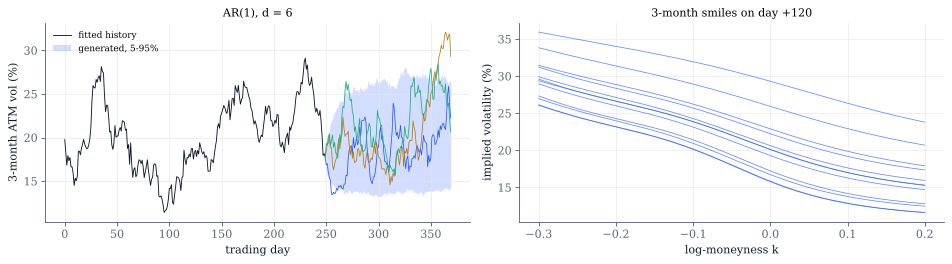

spectral radius 0.9669 per day (half-life 20.6 days); compressed fit inside the spreads: 91.1% of the history's prices
generated weights: min 4.7e-28, largest |mean - 1| 1.1e-14, worst calendar violation of the weights 5.0e-15; smoothing variances nondecreasing: True


In [9]:
def generator(d=6, horizon=120, n_paths=400, seed=17):
    gen = S.fit_generator(hist, d)
    Tm, K, basis = hist["T"], hist["K"], hist["basis"]
    q, v = S.decode(hist["U"], K, Tm, basis, n_expiries=3)
    atm_hist = 100 * S.atm_vol(q, v, K, Tm, 2)
    hp = S.simulate_ar1(gen["m"], gen["A"], gen["Omega"], gen["H"][-1], horizon, n_paths, seed=seed)
    qg, vg = S.decode(gen["u0"] + hp @ gen["Lam"].T, K, Tm, basis)
    atm_gen = 100 * S.atm_vol(qg, vg, K, Tm, 2)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 3.4))
    days = np.arange(len(atm_hist)); fut = days[-1] + np.arange(horizon + 1)
    ax.plot(days, atm_hist, color=INK, lw=0.8, label="fitted history")
    lo, hi = np.percentile(atm_gen, [5, 95], axis=0)
    ax.fill_between(fut, lo, hi, color=COBALT, alpha=0.2, lw=0, label="generated, 5-95%")
    for i, c in zip(range(3), (COBALT, GOLD, GREEN)):
        ax.plot(fut, atm_gen[i], color=c, lw=0.7)
    ax.set(xlabel="trading day", ylabel="3-month ATM vol (%)", title=f"AR(1), d = {d}"); ax.legend(fontsize=8)
    k = np.linspace(-0.3, 0.2, 200); x = np.exp(k)
    for i in range(12):
        c = S.sanos_prices(qg[i, -1, 2], K, x, vg[i, -1, 2])
        ax2.plot(k, iv(c, x, Tm[2]), color=COBALT, lw=0.7, alpha=0.7)
    ax2.set(xlabel="log-moneyness k", ylabel="implied volatility (%)", title=f"3-month smiles on day +{horizon}")
    fig.tight_layout(); plt.show()
    calls = np.einsum("...jn,nl->...jl", qg, np.maximum(K[:, None] - K[None, :], 0.0))
    print(f"spectral radius {gen['rho']:.4f} per day (half-life {np.log(0.5) / np.log(gen['rho']):.1f} days); "
          f"compressed fit inside the spreads: {100 * S.compressed_inside(hist, gen):.1f}% of the history's prices")
    print(f"generated weights: min {qg.min():.1e}, largest |mean - 1| {np.abs(qg @ K - 1).max():.1e}, "
          f"worst calendar violation of the weights {max(0.0, -np.diff(calls, axis=-2).min()):.1e}; "
          f"smoothing variances nondecreasing: {bool((np.diff(vg, axis=-1) > 0).all())}")

generator()

In [10]:
# Explore: compress harder (d = 1, 2) or less; generate further ahead; another seed.
interact(generator,
         d=IntSlider(value=6, min=1, max=12, continuous_update=False, description="d"),
         horizon=IntSlider(value=120, min=20, max=500, step=20, continuous_update=False, description="horizon"),
         n_paths=IntSlider(value=400, min=50, max=1000, step=50, continuous_update=False, description="paths"),
         seed=IntSlider(value=17, min=0, max=50, continuous_update=False, description="seed"));

## 5. Static is not dynamic: drift tests

Each generated surface is free of static arbitrage, but nothing makes the generated prices martingales. We simulate the
spot (lognormal at the front at-the-money volatility, its Gaussian score correlated with the state innovations: a
simplification of DYSANOS eq. (29)) and the one-day returns of floating calls at normalized strikes $x$ for one and three
months, held for a day. The left panel shows the mean return of each instrument with the surface *frozen* (no state
noise): the drift that the spot model alone creates. The right panel shows the $z$-scores of the mean returns on the full
generator, with standard errors computed on the antithetic pairs (path $i$ and its mirror image are strongly negatively
correlated, so treating paths as independent would understate the evidence), and the printout the cross-fitted conditional test
of Proposition 17.13 (DYSANOS Theorem 4.3) with constant and with linear actions, and on each instrument alone. The synthetic
history itself is not free of dynamic arbitrage: its variance has volatility of volatility 0.4, its surfaces are priced with 0.5.

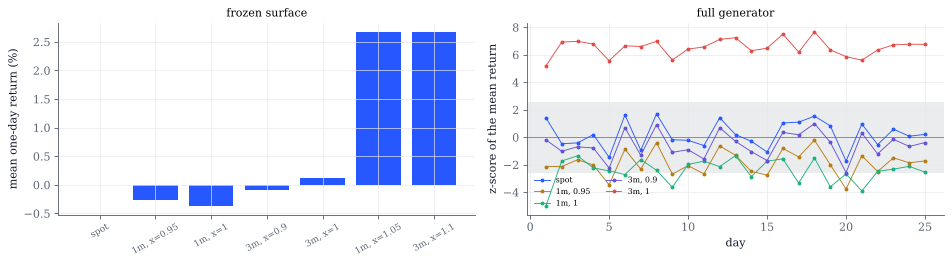

frozen surface z-scores: [  1.4 -31.2  -9.2 -39.5   7.9  19.9  34.5]
full generator: largest |z| 7.67, 38 of 125 beyond 2.576; conditional test T = 30.23 (constant actions), 4.69 (linear in the state and log S); each instrument alone: [0.8, 7.7, 9.3, 1.6, 32.5]


In [11]:
gen6 = S.fit_generator(hist, 6)

def drift(n_paths=4000, n_steps=25, seed=11):
    inst = S.INSTRUMENTS + [(1 / 12, 1.05), (3 / 12, 1.1)]
    labels = ["spot"] + [f"{12 * T:.0f}m, x={x:g}" for T, x in inst]
    mean, z = S.frozen_surface_drift(hist, gen6, instruments=inst)
    dd = S.dynamic_diagnostics(hist, gen6, n_paths=n_paths, n_steps=n_steps, seed=seed)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 3.4))
    ax.bar(range(len(mean)), 100 * mean, color=COBALT)
    ax.set_xticks(range(len(mean)), labels, rotation=30, fontsize=8)
    ax.set(ylabel="mean one-day return (%)", title="frozen surface")
    ax2.axhline(0, color=GREY, lw=0.6)
    for i, lab in enumerate(["spot", "1m, 0.95", "1m, 1", "3m, 0.9", "3m, 1"]):
        ax2.plot(np.arange(1, n_steps + 1), dd["z"][:, i], "o-", ms=2.5, lw=0.8, label=lab)
    ax2.axhspan(-2.576, 2.576, color=GREY, alpha=0.12, lw=0)
    ax2.set(xlabel="day", ylabel="z-score of the mean return", title="full generator"); ax2.legend(fontsize=7, ncol=2)
    fig.tight_layout(); plt.show()
    print(f"frozen surface z-scores: {np.round(z, 1)}")
    print(f"full generator: largest |z| {dd['max_z']:.2f}, {dd['n_z_large']} of {dd['z'].size} beyond 2.576; conditional test "
          f"T = {dd['test_const'][0]:.2f} (constant actions), {dd['test_linear'][0]:.2f} (linear in the state and log S); "
          f"each instrument alone: {[round(t[0], 1) for t in dd['test_single']]}")

drift()

In [12]:
# Explore: fewer paths make the test weaker; more days give it more to find.
interact(drift,
         n_paths=IntSlider(value=4000, min=1000, max=8000, step=1000, continuous_update=False, description="paths"),
         n_steps=IntSlider(value=25, min=5, max=50, step=5, continuous_update=False, description="days"),
         seed=IntSlider(value=11, min=0, max=50, continuous_update=False, description="seed"));

## 6. The martingale behind a SANOS surface

The proof of Theorem 17.8 builds the martingale explicitly: a Markov chain $\xi_j$ on the model strikes, a switch from
$\xi_{j-1}$ to $\xi_j$ at a uniform random time between the expiries, and an independent lognormal factor $Y$. Below, the
chain uses the transitions of a discrete local volatility (Proposition 17.10(i)); a few paths of $Z_T=X_TY_T$ are drawn,
and Monte Carlo prices are compared with the SANOS formula at a maturity between two expiries.

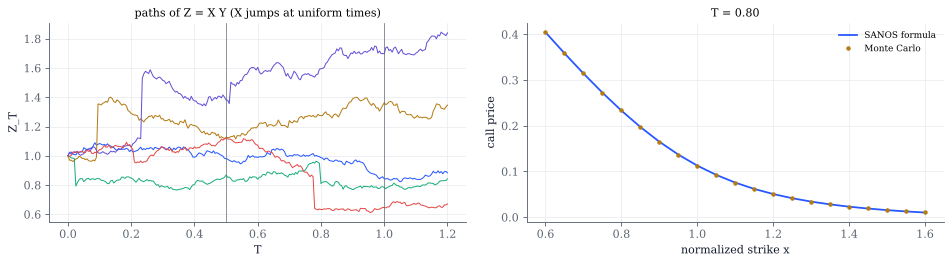

mean of Z_T: 1.0003 (should be 1); largest price gap: 3.0e-04


In [13]:
def martingale(sigma=0.3, eta=0.25, T=0.8, n=200_000, seed=1):
    K = np.exp(np.linspace(-0.6, 0.6, 31)); K[15] = 1.0
    Tj = np.array([0.5, 1.0])
    Sig = np.full((2, K.size), sigma)
    q = S.dlv_densities(K, Sig, Tj)
    Q1 = np.linalg.inv(S.dlv_matrix(K, Sig[0], 0.5)); Q2 = np.linalg.inv(S.dlv_matrix(K, Sig[1], 0.5))
    v = eta * sigma**2 * Tj
    rng = np.random.default_rng(seed)
    i1 = np.argmax(rng.random(n)[:, None] < np.cumsum(Q1[:, 15]), axis=1)          # xi_1, from the unit mass at 1
    i2 = np.argmax(rng.random(n)[:, None] < np.cumsum(Q2, axis=0)[:, i1].T, axis=1)  # xi_2 given xi_1
    U1, U2 = rng.random(n), rng.random(n)
    def X(tt, idx=slice(None)):
        if tt <= 0.5:
            return np.where(U1[idx] <= tt / 0.5, K[i1[idx]], 1.0)
        return np.where(U2[idx] <= min(1.0, (tt - 0.5) / 0.5), K[i2[idx]], K[i1[idx]])
    t = np.linspace(0, 1.2, 241)
    vt = S.smoothing_variance(t, Tj, v)
    W = np.vstack([np.zeros(5), np.cumsum(rng.standard_normal((len(t) - 1, 5)) * np.sqrt(np.diff(vt))[:, None], axis=0)])
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 3.4))
    for p in range(5):
        ax.plot(t, np.array([X(tt, slice(p, p + 1))[0] for tt in t]) * np.exp(W[:, p] - vt / 2), lw=0.9)
    ax.axvline(0.5, color=GREY, lw=0.6); ax.axvline(1.0, color=GREY, lw=0.6)
    ax.set(xlabel="T", ylabel="Z_T", title="paths of Z = X Y (X jumps at uniform times)")
    vT = float(S.smoothing_variance(T, Tj, v))
    Z = X(T) * np.exp(np.sqrt(vT) * rng.standard_normal(n) - vT / 2)
    x = np.linspace(0.6, 1.6, 21)
    mc = np.maximum(Z[:, None] - x[None, :], 0).mean(axis=0)
    exact = S.sanos_surface(q, K, Tj, v, T, x)
    ax2.plot(x, exact, color=COBALT, label="SANOS formula")
    ax2.plot(x, mc, "o", ms=3, color=GOLD, label="Monte Carlo")
    ax2.set(xlabel="normalized strike x", ylabel="call price", title=f"T = {T:.2f}"); ax2.legend(fontsize=8)
    fig.tight_layout(); plt.show()
    print(f"mean of Z_T: {Z.mean():.4f} (should be 1); largest price gap: {np.max(np.abs(mc - exact)):.1e}")

martingale()

In [14]:
# Explore: eta = 0 removes Y and leaves the pure-jump martingale X; move T across the expiries.
interact(martingale,
         sigma=FloatSlider(value=0.3, min=0.05, max=0.8, step=0.05, continuous_update=False, description="Sigma"),
         eta=FloatSlider(value=0.25, min=0.0, max=1.0, step=0.05, continuous_update=False, description="eta"),
         T=FloatSlider(value=0.8, min=0.05, max=1.2, step=0.05, continuous_update=False, description="T"),
         n=IntSlider(value=200_000, min=20_000, max=400_000, step=20_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=1, min=0, max=50, continuous_update=False, description="seed"));

## 7. A real surface (optional download)

`load_quotes` downloads the DAX implied-volatility surface of A. Sepp from QuantLib's test suite (spot $4468.17$, zero
rates by maturity, no dividends, 13 strikes from 3400 to 5600, maturities from 13 to 703 days), converts it to normalized
prices with $F_T=S_0e^{r_TT}$, and attaches assumed half-spreads of `spread` volatility points times the vega. Without
network access it returns the synthetic quotes of Section 1. The mids are checked against Theorem 17.6, and SANOS is fitted
as in Section 2. No data are stored in the repository.

download failed (RuntimeError); using the synthetic market


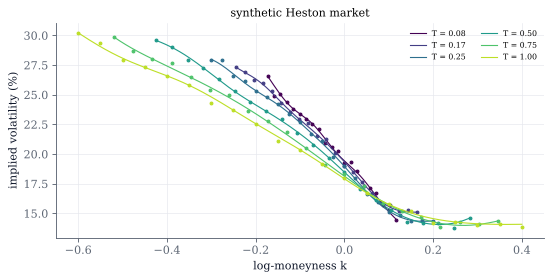

negative butterflies of adjacent mids, by expiry: [0, 0, 1, 1, 2, 2]
SANOS (eta = 0.25): 100.0% inside the assumed spreads; checks: density -6.9e-10, calendar -8.0e-12


In [15]:
QL_URL = "https://raw.githubusercontent.com/lballabio/QuantLib/master/test-suite/hestonmodel.cpp"

def load_quotes(spread=0.5, timeout=10):
    """(quotes, expiries, source): the DAX surface from QuantLib's test suite, or the synthetic market offline.
    Set the environment variable IEOR222_OFFLINE=1 to skip the download."""
    try:
        if os.environ.get("IEOR222_OFFLINE"):
            raise RuntimeError("offline mode")
        src = urllib.request.urlopen(QL_URL, timeout=timeout).read().decode("utf-8", "replace")
        body = src[src.index("getDAXCalibrationMarketData"):]
        def arr(name):
            m = re.search(name + r"\[\]\s*=\s*\{([^}]*)\}", body)
            return np.array([float(a) for a in m.group(1).split(",") if a.strip()])
        t, r, vol, strikes = arr("Integer t"), arr("Rate r"), arr("Volatility v"), arr("Real strike")
        S0 = float(re.search(r"SimpleQuote>\(([\d.]+)\)", body).group(1))
        T = t / 365.0
        F = S0 * np.exp(r * T)
        vol = vol.reshape(len(strikes), len(T))
        quotes = []
        for j, Tj in enumerate(T):
            x = strikes / F[j]
            mid = black_normalized(np.log(x), vol[:, j] * np.sqrt(Tj))
            quotes.append(S.make_quotes(Tj, x, mid, half_spread_vol=spread / 100, noise=0.0, w=vol[:, j] ** 2 * Tj))
        return quotes, T, "DAX surface (A. Sepp, via QuantLib)"
    except Exception as err:
        print(f"download failed ({type(err).__name__}); using the synthetic market")
        quotes = S.heston_quotes(S.T_MODEL, S.HESTON, seed=17, half_spread_vol=spread / 100)
        return quotes, S.T_MODEL, "synthetic Heston market"

def real(spread=0.5):
    eta = S.ETA
    quotes, T, source = load_quotes(spread)
    bad = [S.grid_arbitrage(q["x"], q["mid"][None, :])["n_butterfly"] for q in quotes]
    K = S.strike_grid(T)
    V = np.maximum.accumulate([S.atm_variance_from_quotes(q) for q in quotes]); v = eta * V
    fit = S.sanos_calibrate(K, quotes, v)
    inside, _ = S.within_bid_ask(fit["c"], quotes)
    fig, ax = plt.subplots(figsize=(7, 3.6))
    for j in range(len(T)):
        qt, c = quotes[j], plt.cm.viridis(0.9 * j / max(len(T) - 1, 1))
        k = np.linspace(np.log(qt["x"][0]), np.log(qt["x"][-1]), 200); x = np.exp(k)
        ax.plot(np.log(qt["x"]), iv(qt["mid"], qt["x"], T[j]), "o", ms=2.5, color=c)
        ax.plot(k, iv(S.sanos_surface(fit["q"], K, T, v, T[j], x), x, T[j]), color=c, lw=1, label=f"T = {T[j]:.2f}")
    ax.set(xlabel="log-moneyness k", ylabel="implied volatility (%)", title=source); ax.legend(fontsize=7, ncol=2)
    fig.tight_layout(); plt.show()
    xg = np.exp(np.linspace(-1.0, 0.8, 801)); Tg = np.linspace(0.01, 1.1 * T[-1], 60)
    chk = S.surface_checks(lambda t, xx: S.sanos_surface(fit["q"], K, T, v, t, xx), Tg, xg)
    print(f"negative butterflies of adjacent mids, by expiry: {bad}")
    print(f"SANOS (eta = {eta}): {100 * inside:.1f}% inside the assumed spreads; checks: density {chk['butterfly']:.1e}, "
          f"calendar {chk['calendar']:.1e}")

real()

In [16]:
# Explore: how narrow can the assumed spreads be before the fit misses quotes?
interact(real,
         spread=FloatSlider(value=0.5, min=0.02, max=2.0, step=0.02, continuous_update=False, description="spread (pts)"));

## Things to try

* In Section 1, set `noise` to 0. The mids are then Heston prices: are there still concave kinks? Why does the cubic spline
  still oscillate in the wings, where the spreads are at their floor?
* In Section 2, find the narrowest spread at which every price is still inside its spread. Which expiries fail first?
* In Section 3, how does the gap to Dupire behave as the grid is refined? Where is it largest, and why there?
* In Section 4, compress to `d = 1`: does the generator still reproduce the swings of the at-the-money volatility? What do
  you lose in the smiles?
* In Section 5, which instrument drifts with the surface frozen, and in which direction? Relate the sign to the skew.
* In Section 6, set `eta = 0` and look at the paths: what kind of martingale is left?
* In Section 7, with network access and `IEOR222_OFFLINE` unset, compare the negative butterflies of the DAX mids with those
  of the synthetic market of Section 1.